In [1]:
# %% [markdown]
# # Verificación Post-Imputación - PISA 2022
# ## Validación de calidad de imputación por mediana y "Missing"
# 
# Este notebook verifica:
# 1. Cambios en distribuciones de variables numéricas
# 2. Impacto en correlaciones
# 3. Detección de patrones anómales
# 4. Validación de imputación categórica
# 5. Recomendaciones para mejorar imputación si es necesario

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import ks_2samp, mannwhitneyu
import warnings
warnings.filterwarnings('ignore')

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

print("✓ Librerías cargadas")

✓ Librerías cargadas


In [2]:
# %% [markdown]
# ## 1. Cargar datos
# 
# **IMPORTANTE:** Necesitas tener guardados:
# - El dataset ANTES de imputar (`df_pre_imputacion.csv`)
# - El dataset DESPUÉS de imputar (`df_post_imputacion.csv`)
# 
# Si no los tienes separados, necesitarás recrear la versión pre-imputación
# eliminando las filas/columnas procesadas.

# %%
# OPCIÓN A: Si tienes ambos datasets guardados
try:
    df_pre = pd.read_csv('../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv')
    df_post = pd.read_csv('../data_ready/COLLECT_COMP_dataset_treated.csv')
    print("✓ Datasets cargados desde archivos")
    tiene_pre = True
except FileNotFoundError:
    print("⚠️ No se encontraron archivos pre/post imputación")
    print("Cargaré solo el dataset imputado para análisis parcial")
    df_post = pd.read_csv('dataset_limpio_final.csv')  # Ajusta el nombre
    tiene_pre = False

print(f"\nDimensiones dataset post-imputación: {df_post.shape}")
if tiene_pre:
    print(f"Dimensiones dataset pre-imputación: {df_pre.shape}")

✓ Datasets cargados desde archivos

Dimensiones dataset post-imputación: (6968, 4942)
Dimensiones dataset pre-imputación: (6968, 7147)


In [25]:
df_post['LANGN'].apply(type).value_counts()

LANGN
<class 'str'>    6968
Name: count, dtype: int64

In [3]:
# %% [markdown]
# ## 2. Identificar variables numéricas vs categóricas

# %%
# Identificar tipos de variables
numericas = df_post.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df_post.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Variables numéricas: {len(numericas)}")
print(f"Variables categóricas: {len(categoricas)}")

# Mostrar muestra de cada tipo
print("\n📊 Primeras 10 variables numéricas:")
print(numericas[:10])

print("\n📋 Primeras 10 variables categóricas:")
print(categoricas[:10])

# Identificar variables que podrían haber tenido imputación categórica
vars_con_missing = [col for col in categoricas if 'Missing' in df_post[col].unique()]
print(f"\n⚠️ Variables con categoría 'Missing': {len(vars_con_missing)}")
if len(vars_con_missing) > 0:
    print("Ejemplos:", vars_con_missing[:5])

Variables numéricas: 2705
Variables categóricas: 2237

📊 Primeras 10 variables numéricas:
['CNTSCHID', 'CNTSTUID', 'CM033Q01TT', 'CM033Q01F', 'CM033Q01A', 'CM474Q01TT', 'CM474Q01F', 'CM474Q01A', 'CM155Q02TT', 'CM155Q02F']

📋 Primeras 10 variables categóricas:
['STRATUM', 'BOOKID', 'RDESIGN', 'RCORE_TEST', 'RCORE_PERF', 'RS1_LEV', 'RS1_TEST', 'RCO1S_PERF', 'RS2_LEV', 'RS2_TEST']

⚠️ Variables con categoría 'Missing': 1984
Ejemplos: ['CM033Q01S', 'DM033Q01R', 'CM474Q01S', 'DM474Q01R', 'DM155Q02C']


In [4]:
# %% [markdown]
# ## 3. Análisis de distribuciones (si tienes datos pre-imputación)

# %%
if tiene_pre:
    def comparar_distribuciones(df_antes, df_despues, variable, n_bins=50):
        """
        Compara la distribución de una variable antes y después de imputar
        """
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        
        # Datos sin NaN
        antes_clean = df_antes[variable].dropna()
        despues_clean = df_despues[variable].dropna()
        
        # 1. Histogramas superpuestos
        axes[0].hist(antes_clean, bins=n_bins, alpha=0.5, label='Pre-imputación', 
                     color='blue', density=True)
        axes[0].hist(despues_clean, bins=n_bins, alpha=0.5, label='Post-imputación', 
                     color='red', density=True)
        axes[0].set_xlabel('Valor')
        axes[0].set_ylabel('Densidad')
        axes[0].set_title(f'Distribución: {variable}')
        axes[0].legend()
        axes[0].grid(alpha=0.3)
        
        # 2. Q-Q plot
        stats.probplot(despues_clean, dist="norm", plot=axes[1])
        axes[1].set_title('Q-Q Plot (Post-imputación)')
        axes[1].grid(alpha=0.3)
        
        # 3. Boxplots comparativos
        data_plot = pd.DataFrame({
            'Pre': antes_clean,
            'Post': despues_clean
        })
        data_plot.boxplot(ax=axes[2])
        axes[2].set_ylabel('Valor')
        axes[2].set_title('Comparación Boxplot')
        axes[2].grid(alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Estadísticas comparativas
        print(f"\n{'='*70}")
        print(f"COMPARACIÓN ESTADÍSTICA: {variable}")
        print(f"{'='*70}")
        
        stats_comp = pd.DataFrame({
            'Métrica': ['N', 'Media', 'Mediana', 'DE', 'Mín', 'Máx', 'P25', 'P75', 'Asimetría', 'Curtosis'],
            'Pre-imputación': [
                len(antes_clean),
                antes_clean.mean(),
                antes_clean.median(),
                antes_clean.std(),
                antes_clean.min(),
                antes_clean.max(),
                antes_clean.quantile(0.25),
                antes_clean.quantile(0.75),
                antes_clean.skew(),
                antes_clean.kurtosis()
            ],
            'Post-imputación': [
                len(despues_clean),
                despues_clean.mean(),
                despues_clean.median(),
                despues_clean.std(),
                despues_clean.min(),
                despues_clean.max(),
                despues_clean.quantile(0.25),
                despues_clean.quantile(0.75),
                despues_clean.skew(),
                despues_clean.kurtosis()
            ]
        })
        
        # Calcular cambio porcentual
        stats_comp['Cambio_%'] = (
            (stats_comp['Post-imputación'] - stats_comp['Pre-imputación']) / 
            stats_comp['Pre-imputación'] * 100
        ).round(2)
        
        print(stats_comp.to_string(index=False))
        
        # Pruebas estadísticas
        ks_stat, ks_pval = ks_2samp(antes_clean, despues_clean)
        mw_stat, mw_pval = mannwhitneyu(antes_clean, despues_clean, alternative='two-sided')
        
        print(f"\n📊 PRUEBAS ESTADÍSTICAS:")
        print(f"   Kolmogorov-Smirnov: D={ks_stat:.4f}, p-valor={ks_pval:.4f}")
        print(f"   Mann-Whitney U: U={mw_stat:.0f}, p-valor={mw_pval:.4f}")
        
        if ks_pval < 0.05:
            print("   ⚠️ Las distribuciones son significativamente diferentes")
        else:
            print("   ✓ Las distribuciones no difieren significativamente")
        
        return stats_comp
    
    print("✓ Función de comparación definida")
else:
    print("⚠️ Necesitas datos pre-imputación para comparación completa")

✓ Función de comparación definida


In [5]:
# %% [markdown]
# ## 4. Analizar variables clave (PERSONALIZAR)

# %%
# IMPORTANTE: Personaliza esta lista con tus variables más importantes
# Ejemplos comunes en PISA:
# variables_criticas = [
#     'PV1MATH', 'PV1READ', 'PV1SCIE',  # Rendimiento
#     'ESCS', 'HOMEPOS', 'WEALTH',      # Socioeconómico
#     'ST004D01T',                       # Género
# ]

variables_criticas = [
    # Nivel 1: Outcome
    'PV9MATH',        # Rendimiento en matemáticas (valor plausible)  
    'PV5READ',        # Rendimiento en lectura  

    # Nivel 2: Predictores principales / socioeconómicos
    'ESCS',           # Estatus socioeconómico general  
    'HOMEPOS',        # Bienes del hogar — riqueza material  
    'HISEI',          # Ocupación de los padres  

    # Controles estándar
    'ST004D01T',      # Género  
    'AGE',            # Edad  
    'IMMIG',          # Status migratorio  
    'LANGN',          # Idioma nativo del estudiante respecto al idioma de prueba  

    # Predictores lingüísticos/contexto de idioma
    'LANGTEST_COG',   # Habilidad cognitiva del idioma / test de idioma  
    'LANGTEST_PAQ',   # Quizás percepción de habilidad lingüística  

    # (Opcional: descomponer ESCS si interesan componentes específicos)
    # 'HOMEPOS', 'HISEI' ya incluidos
]


# Detectar automáticamente algunas variables clave si existen
auto_vars = []
for pattern in ['MATH', 'READ', 'SCIE', 'ESCS', 'HOMEPOS']:
    matches = [col for col in numericas if pattern in col.upper()]
    if matches:
        auto_vars.extend(matches[:2])  # Máximo 2 por patrón

variables_criticas = list(set(variables_criticas + auto_vars))[:10]  # Máximo 10

print(f"Variables a analizar: {len(variables_criticas)}")
print(variables_criticas)

Variables a analizar: 10
['AGE', 'LANGN', 'HOMEPOS', 'MATHEF21', 'ST004D01T', 'PV2READ', 'MATHEFF', 'IMMIG', 'HISEI', 'PV1SCIE']



######################################################################
Analizando: AGE
######################################################################


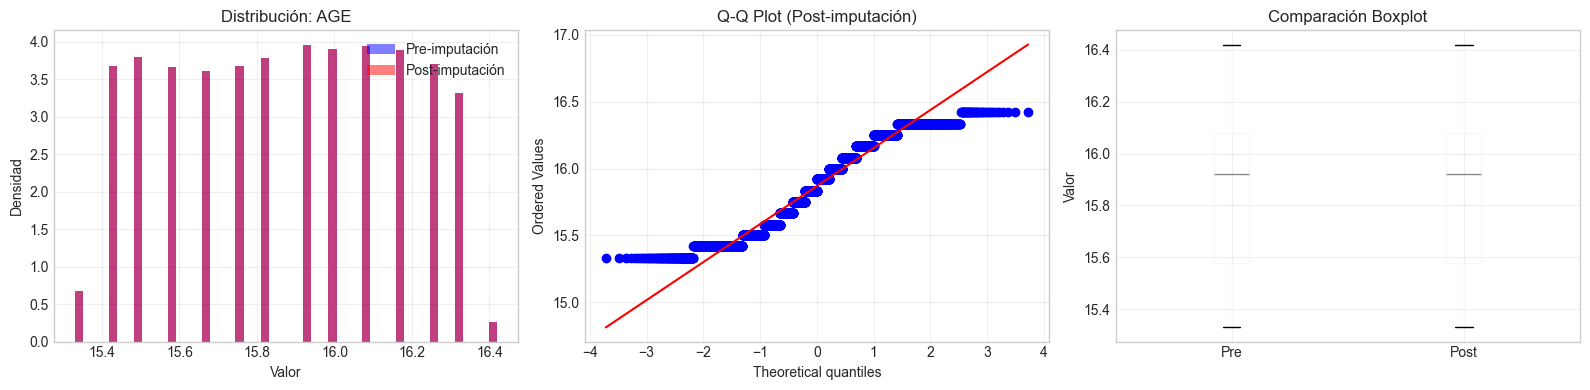


COMPARACIÓN ESTADÍSTICA: AGE
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     6968.000000      6968.000000       0.0
    Media       15.869546        15.869546       0.0
  Mediana       15.920000        15.920000       0.0
       DE        0.291191         0.291191       0.0
      Mín       15.330000        15.330000       0.0
      Máx       16.420000        16.420000       0.0
      P25       15.580000        15.580000       0.0
      P75       16.080000        16.080000       0.0
Asimetría       -0.028913        -0.028913      -0.0
 Curtosis       -1.175484        -1.175484      -0.0

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.0000, p-valor=1.0000
   Mann-Whitney U: U=24276512, p-valor=1.0000
   ✓ Las distribuciones no difieren significativamente

######################################################################
Analizando: LANGN
######################################################################
⚠️ Error analizando LANGN: ufunc 'divide' not suppor

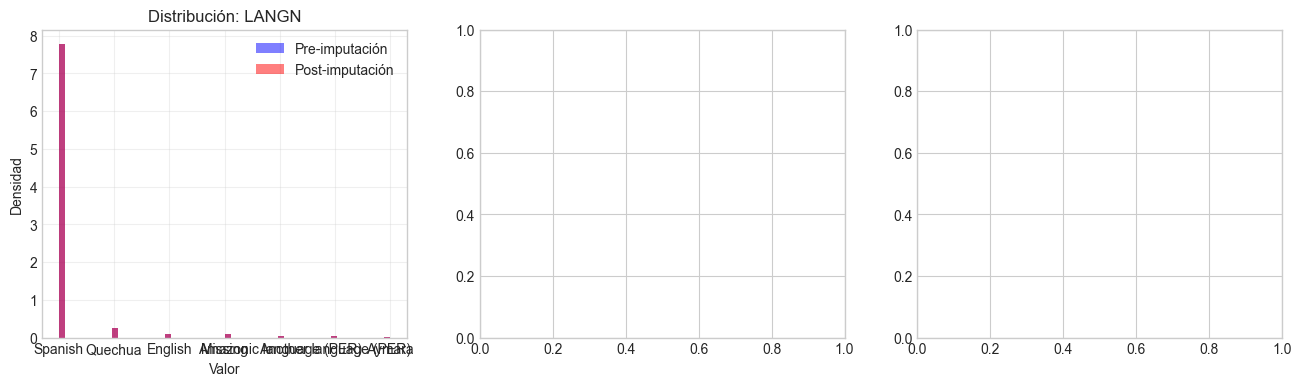

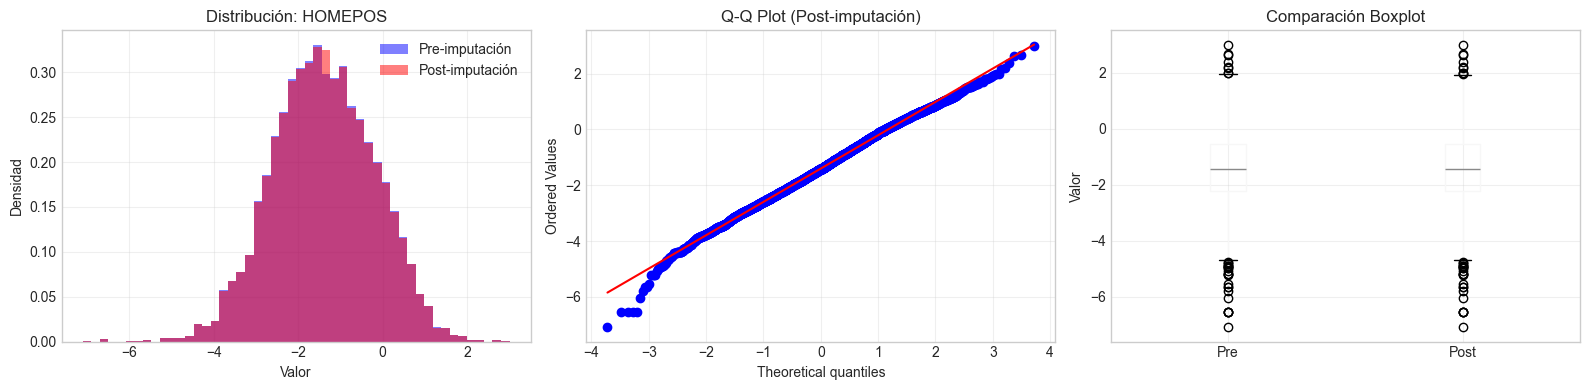


COMPARACIÓN ESTADÍSTICA: HOMEPOS
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     6927.000000      6968.000000      0.59
    Media       -1.402810        -1.402952      0.01
  Mediana       -1.426900        -1.426900     -0.00
       DE        1.198842         1.195310     -0.29
      Mín       -7.096400        -7.096400     -0.00
      Máx        3.002900         3.002900      0.00
      P25       -2.234550        -2.229625     -0.22
      P75       -0.556900        -0.560875      0.71
Asimetría       -0.084204        -0.084097     -0.13
 Curtosis        0.023722         0.041567     75.22

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.0029, p-valor=1.0000
   Mann-Whitney U: U=24133668, p-valor=1.0000
   ✓ Las distribuciones no difieren significativamente

######################################################################
Analizando: MATHEF21
######################################################################


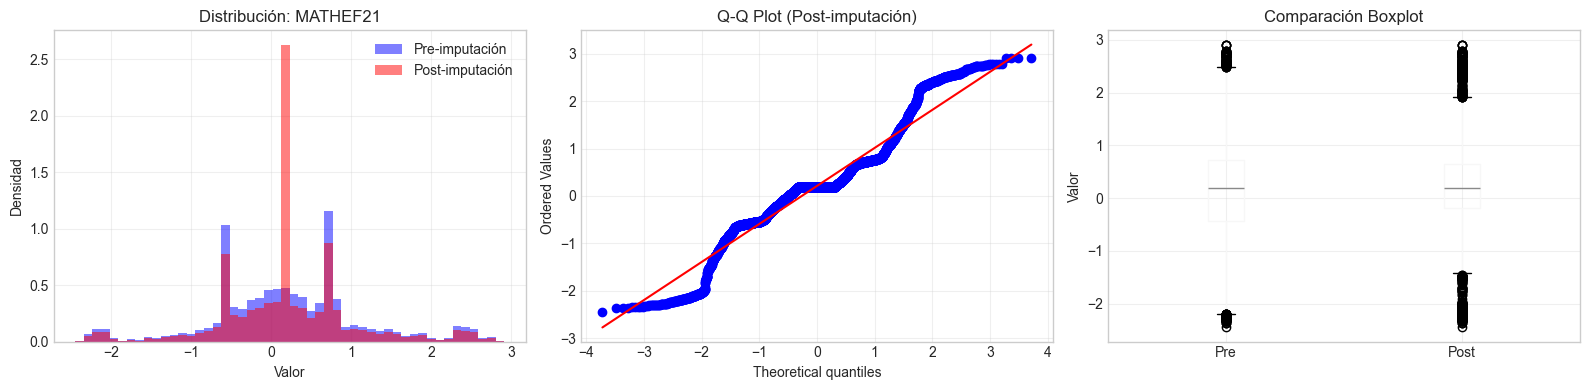


COMPARACIÓN ESTADÍSTICA: MATHEF21
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     5274.000000      6968.000000     32.12
    Media        0.217084         0.209965     -3.28
  Mediana        0.187800         0.187800      0.00
       DE        0.953943         0.830000    -12.99
      Mín       -2.451900        -2.451900     -0.00
      Máx        2.912600         2.912600      0.00
      P25       -0.440650        -0.192975    -56.21
      P75        0.731400         0.651325    -10.95
Asimetría        0.125711         0.170166     35.36
 Curtosis        0.707187         1.900919    168.80

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.1215, p-valor=0.0000
   Mann-Whitney U: U=18373769, p-valor=0.9965
   ⚠️ Las distribuciones son significativamente diferentes

######################################################################
Analizando: ST004D01T
######################################################################
⚠️ Error analizando ST004D01T: ufunc 'd

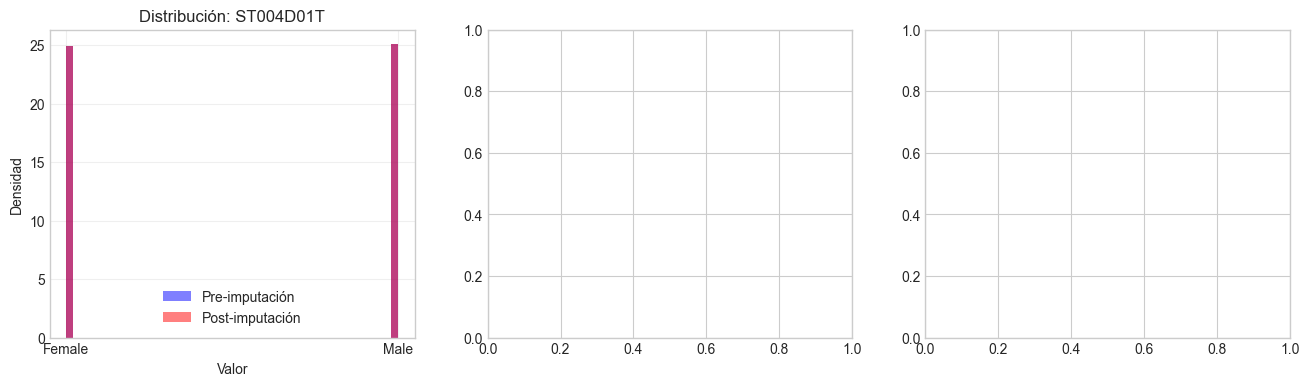

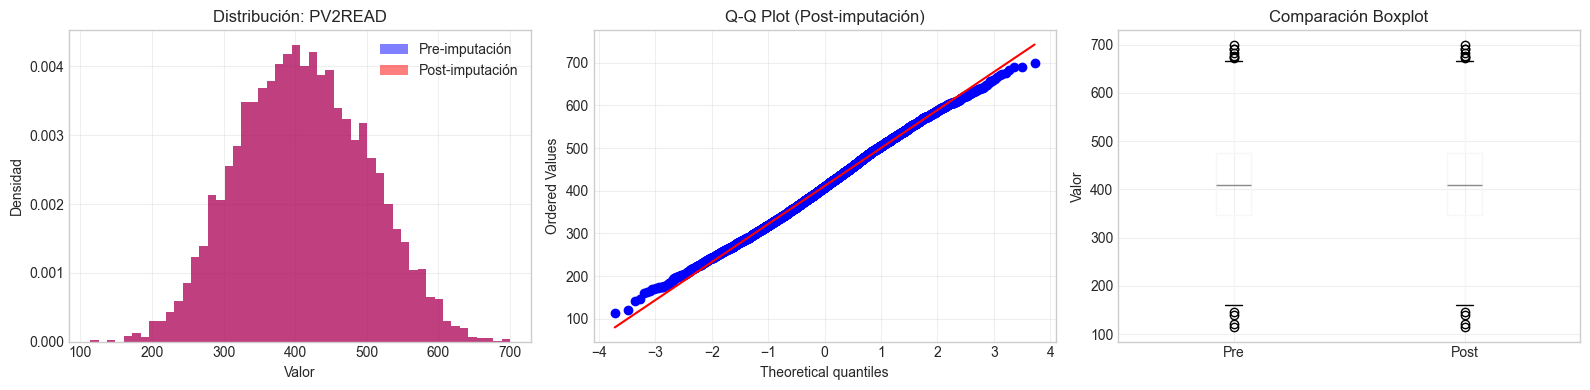


COMPARACIÓN ESTADÍSTICA: PV2READ
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     6968.000000      6968.000000       0.0
    Media      411.141147       411.141147       0.0
  Mediana      408.721500       408.721500       0.0
       DE       89.250759        89.250759       0.0
      Mín      113.874000       113.874000       0.0
      Máx      700.146000       700.146000       0.0
      P25      345.874500       345.874500       0.0
      P75      474.668500       474.668500       0.0
Asimetría        0.066244         0.066244       0.0
 Curtosis       -0.373456        -0.373456      -0.0

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.0000, p-valor=1.0000
   Mann-Whitney U: U=24276512, p-valor=1.0000
   ✓ Las distribuciones no difieren significativamente

######################################################################
Analizando: MATHEFF
######################################################################


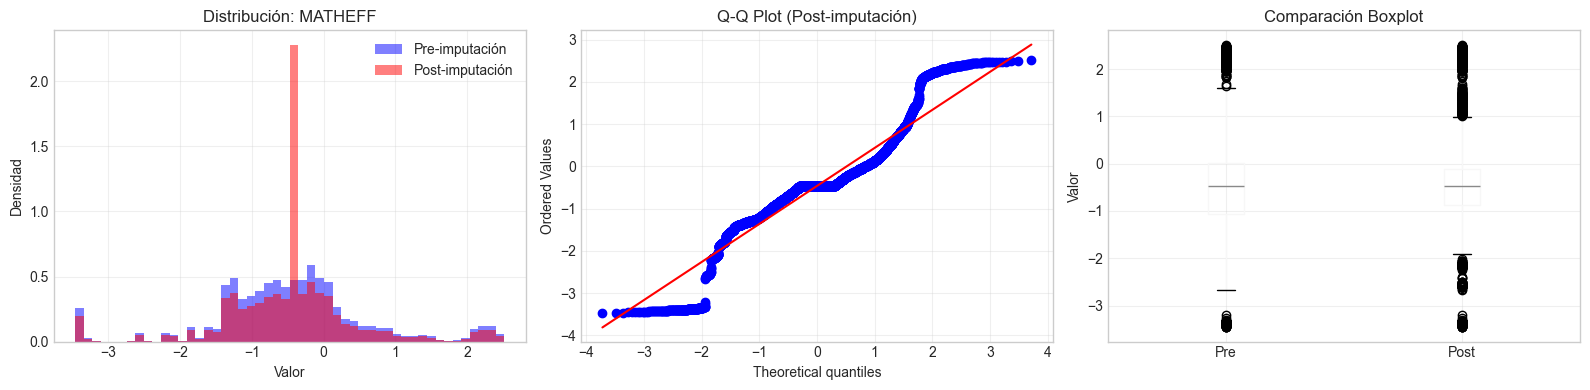


COMPARACIÓN ESTADÍSTICA: MATHEFF
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     5373.000000      6968.000000     29.69
    Media       -0.462514        -0.463930      0.31
  Mediana       -0.468700        -0.468700     -0.00
       DE        1.078777         0.947280    -12.19
      Mín       -3.462600        -3.462600     -0.00
      Máx        2.519100         2.519100      0.00
      P25       -1.065700        -0.873700    -18.02
      P75        0.016100        -0.122600   -861.49
Asimetría        0.090656         0.107717     18.82
 Curtosis        1.487296         2.819555     89.58

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.1143, p-valor=0.0000
   Mann-Whitney U: U=18717937, p-valor=0.9935
   ⚠️ Las distribuciones son significativamente diferentes

######################################################################
Analizando: IMMIG
######################################################################
⚠️ Error analizando IMMIG: ufunc 'divide' no

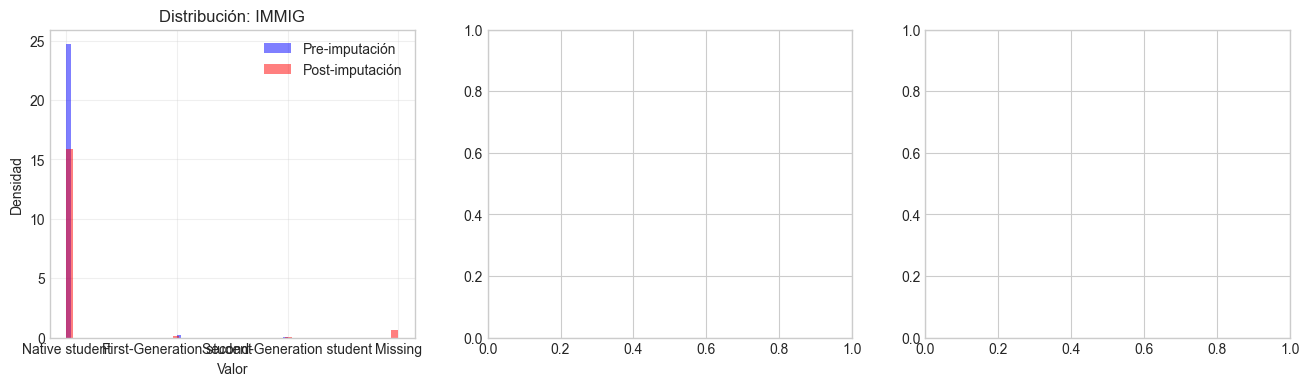

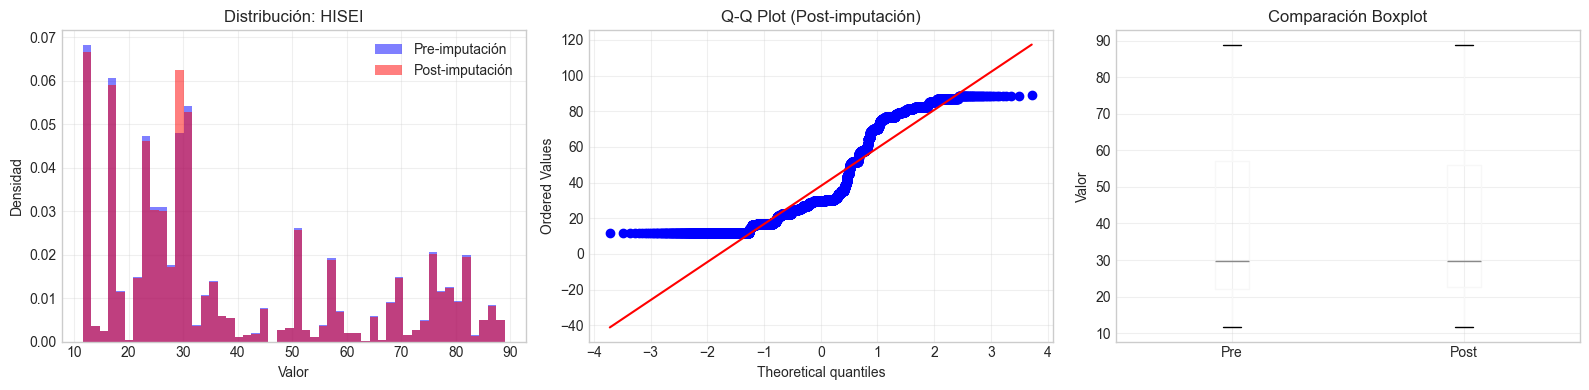


COMPARACIÓN ESTADÍSTICA: HISEI
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     6800.000000      6968.000000      2.47
    Media       38.270226        38.064320     -0.54
  Mediana       29.730000        29.730000      0.00
       DE       23.167840        22.924270     -1.05
      Mín       11.560000        11.560000      0.00
      Máx       88.960000        88.960000      0.00
      P25       21.977500        22.570000      2.70
      P75       57.030000        56.000000     -1.81
Asimetría        0.786008         0.817467      4.00
 Curtosis       -0.754691        -0.684840     -9.26

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.0116, p-valor=0.7415
   Mann-Whitney U: U=23700692, p-valor=0.9675
   ✓ Las distribuciones no difieren significativamente

######################################################################
Analizando: PV1SCIE
######################################################################


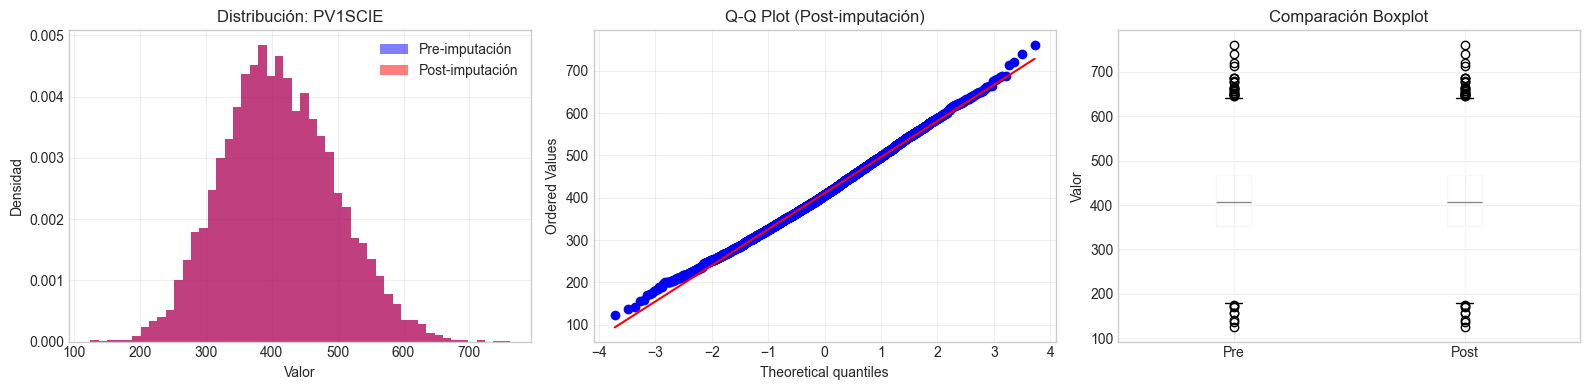


COMPARACIÓN ESTADÍSTICA: PV1SCIE
  Métrica  Pre-imputación  Post-imputación  Cambio_%
        N     6968.000000      6968.000000       0.0
    Media      410.835228       410.835228       0.0
  Mediana      406.914000       406.914000       0.0
       DE       85.352398        85.352398       0.0
      Mín      124.045000       124.045000       0.0
      Máx      761.870000       761.870000       0.0
      P25      351.774500       351.774500       0.0
      P75      468.523250       468.523250       0.0
Asimetría        0.192996         0.192996       0.0
 Curtosis       -0.103963        -0.103963      -0.0

📊 PRUEBAS ESTADÍSTICAS:
   Kolmogorov-Smirnov: D=0.0000, p-valor=1.0000
   Mann-Whitney U: U=24276512, p-valor=1.0000
   ✓ Las distribuciones no difieren significativamente

RESUMEN DE CAMBIOS EN VARIABLES CLAVE
variable  cambio_media_%  cambio_DE_%
     AGE            0.00         0.00
 HOMEPOS            0.01        -0.29
MATHEF21           -3.28       -12.99
 PV2READ          

In [6]:
# %% [markdown]
# ## 5. Comparación detallada de variables clave

# %%
if tiene_pre and len(variables_criticas) > 0:
    resultados_comparacion = []
    
    for var in variables_criticas:
        if var in df_pre.columns and var in df_post.columns:
            print(f"\n{'#'*70}")
            print(f"Analizando: {var}")
            print(f"{'#'*70}")
            
            try:
                stats_comp = comparar_distribuciones(df_pre, df_post, var)
                resultados_comparacion.append({
                    'variable': var,
                    'cambio_media_%': stats_comp[stats_comp['Métrica']=='Media']['Cambio_%'].values[0],
                    'cambio_DE_%': stats_comp[stats_comp['Métrica']=='DE']['Cambio_%'].values[0]
                })
            except Exception as e:
                print(f"⚠️ Error analizando {var}: {e}")
    
    # Resumen de cambios
    if resultados_comparacion:
        df_cambios = pd.DataFrame(resultados_comparacion)
        print("\n" + "="*70)
        print("RESUMEN DE CAMBIOS EN VARIABLES CLAVE")
        print("="*70)
        print(df_cambios.to_string(index=False))
        
        # Alertas
        print("\n🚨 ALERTAS:")
        alertas_media = df_cambios[abs(df_cambios['cambio_media_%']) > 5]
        alertas_de = df_cambios[abs(df_cambios['cambio_DE_%']) > 10]
        
        if len(alertas_media) > 0:
            print(f"   ⚠️ {len(alertas_media)} variables con cambio >5% en media:")
            print("   ", alertas_media['variable'].tolist())
        else:
            print("   ✓ Ninguna variable con cambio significativo en media")
            
        if len(alertas_de) > 0:
            print(f"   ⚠️ {len(alertas_de)} variables con cambio >10% en DE:")
            print("   ", alertas_de['variable'].tolist())
        else:
            print("   ✓ Ninguna variable con cambio significativo en DE")
else:
    print("⚠️ Comparación detallada requiere datos pre-imputación")

Analizando cambios en correlaciones...


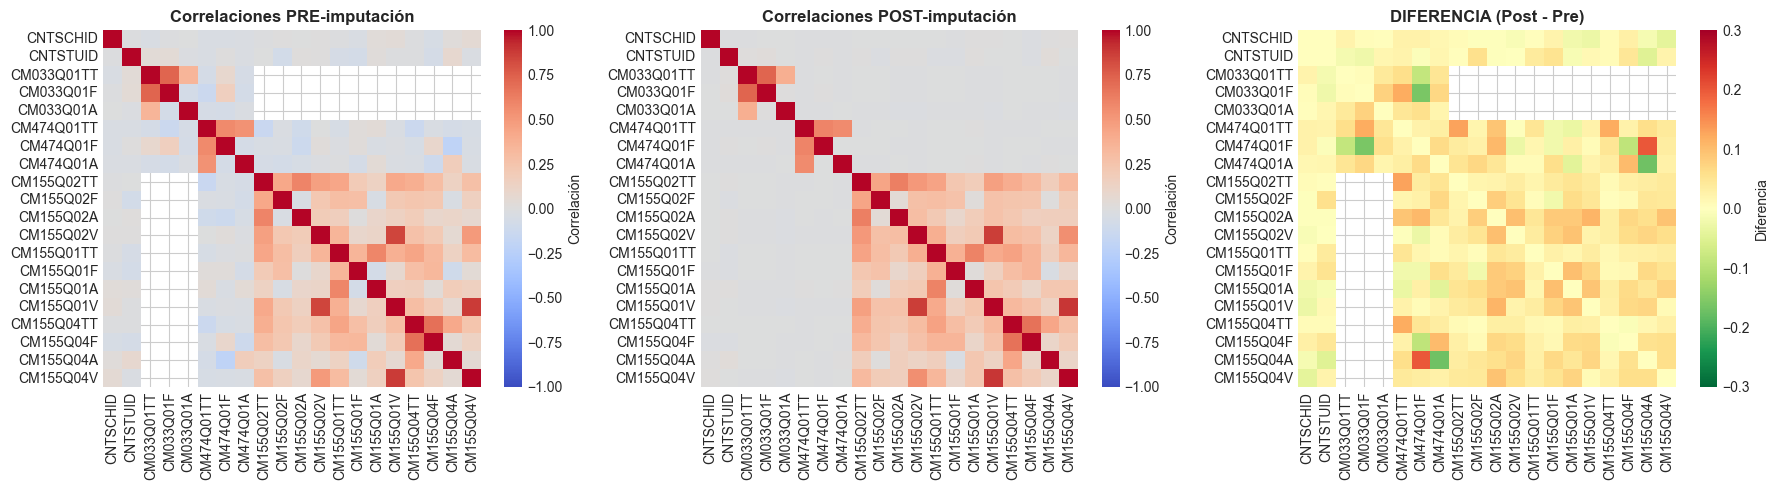


CAMBIOS SIGNIFICATIVOS EN CORRELACIONES (|Δr| > 0.1)
Variable 1 Variable 2  Corr Pre  Corr Post  Diferencia
 CM474Q01F  CM155Q04A -0.210911  -0.009923    0.200988
 CM474Q01A  CM155Q04A  0.175247   0.006355   -0.168892
 CM033Q01F  CM474Q01F  0.161372   0.001605   -0.159766
CM474Q01TT CM155Q02TT -0.141775  -0.011033    0.130741
CM474Q01TT CM155Q04TT -0.129259  -0.008654    0.120605
 CM033Q01F CM474Q01TT -0.131602  -0.011838    0.119764
 CM155Q02A  CM155Q01V  0.147373   0.258262    0.110889
 CM474Q01F  CM155Q02A -0.117533  -0.011720    0.105813
 CM474Q01A  CM155Q04F -0.115952  -0.012512    0.103441

🚨 Se encontraron 9 pares de variables con cambios >|0.1|


In [7]:
# %% [markdown]
# ## 6. Análisis de correlaciones

# %%
def comparar_correlaciones(df_antes, df_despues, vars_numericas, umbral=0.1):
    """
    Compara matrices de correlación antes y después de imputar
    """
    # Seleccionar solo numéricas comunes
    vars_comunes = [v for v in vars_numericas if v in df_antes.columns and v in df_despues.columns]
    
    if len(vars_comunes) < 2:
        print("⚠️ Insuficientes variables para análisis de correlación")
        return None
    
    # Limitar a primeras 20 variables por visualización
    vars_analisis = vars_comunes[:20]
    
    # Calcular correlaciones
    corr_antes = df_antes[vars_analisis].corr()
    corr_despues = df_despues[vars_analisis].corr()
    diferencia = corr_despues - corr_antes
    
    # Visualización
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Correlaciones antes
    sns.heatmap(corr_antes, annot=False, cmap='coolwarm', center=0, 
                vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Correlación'})
    axes[0].set_title('Correlaciones PRE-imputación', fontweight='bold')
    
    # Correlaciones después
    sns.heatmap(corr_despues, annot=False, cmap='coolwarm', center=0,
                vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Correlación'})
    axes[1].set_title('Correlaciones POST-imputación', fontweight='bold')
    
    # Diferencia
    sns.heatmap(diferencia, annot=False, cmap='RdYlGn_r', center=0,
                vmin=-0.3, vmax=0.3, ax=axes[2], cbar_kws={'label': 'Diferencia'})
    axes[2].set_title('DIFERENCIA (Post - Pre)', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Identificar cambios significativos
    cambios_significativos = []
    n = len(diferencia)
    for i in range(n):
        for j in range(i+1, n):
            cambio = diferencia.iloc[i, j]
            if abs(cambio) > umbral:
                cambios_significativos.append({
                    'Variable 1': diferencia.index[i],
                    'Variable 2': diferencia.columns[j],
                    'Corr Pre': corr_antes.iloc[i, j],
                    'Corr Post': corr_despues.iloc[i, j],
                    'Diferencia': cambio
                })
    
    if cambios_significativos:
        df_cambios = pd.DataFrame(cambios_significativos).sort_values(
            'Diferencia', ascending=False, key=abs
        )
        print("\n" + "="*80)
        print(f"CAMBIOS SIGNIFICATIVOS EN CORRELACIONES (|Δr| > {umbral})")
        print("="*80)
        print(df_cambios.to_string(index=False))
        
        print(f"\n🚨 Se encontraron {len(cambios_significativos)} pares de variables con cambios >|{umbral}|")
    else:
        print(f"\n✓ No hay cambios significativos en correlaciones (todos |Δr| < {umbral})")
    
    return diferencia

if tiene_pre:
    print("Analizando cambios en correlaciones...")
    diff_corr = comparar_correlaciones(df_pre, df_post, numericas, umbral=0.1)
else:
    print("⚠️ Análisis de correlaciones requiere datos pre-imputación")

In [8]:
# %% [markdown]
# ## 7. Detección de patrones anómales

# %%
def detectar_patrones_anomalos(df, vars_numericas):
    """
    Detecta patrones anómales introducidos por imputación
    """
    print("\n" + "="*80)
    print("DETECCIÓN DE PATRONES ANÓMALES")
    print("="*80)
    
    anomalias = []
    
    # 1. Concentración excesiva en mediana
    print("\n1️⃣ CONCENTRACIÓN EN VALORES CENTRALES:")
    for var in vars_numericas[:10]:  # Analizar primeras 10
        if var in df.columns:
            data = df[var].dropna()
            if len(data) > 0:
                mediana = data.median()
                # Contar valores exactamente = mediana
                pct_en_mediana = (data == mediana).sum() / len(data) * 100
                
                if pct_en_mediana > 10:  # Umbral: >10% en un valor exacto es sospechoso
                    anomalias.append({
                        'variable': var,
                        'tipo': 'Concentración en mediana',
                        'pct': pct_en_mediana
                    })
                    print(f"   ⚠️ {var}: {pct_en_mediana:.1f}% en mediana ({mediana:.2f})")
    
    # 2. Pérdida de variabilidad
    print("\n2️⃣ PÉRDIDA DE VARIABILIDAD:")
    for var in vars_numericas[:10]:
        if var in df.columns:
            data = df[var].dropna()
            if len(data) > 0:
                cv = data.std() / abs(data.mean()) if data.mean() != 0 else 0
                if cv < 0.05:  # Coeficiente de variación muy bajo
                    anomalias.append({
                        'variable': var,
                        'tipo': 'Baja variabilidad',
                        'cv': cv
                    })
                    print(f"   ⚠️ {var}: CV={cv:.4f} (muy baja variabilidad)")
    
    # 3. Valores fuera de rangos esperados (depende del contexto)
    print("\n3️⃣ VERIFICAR MANUALMENTE:")
    print("   • Revisa si hay valores imposibles (ej: edades negativas)")
    print("   • Verifica combinaciones ilógicas de variables")
    print("   • Comprueba que las escalas sean coherentes con PISA")
    
    if len(anomalias) == 0:
        print("\n✓ No se detectaron patrones anómales obvios")
    else:
        print(f"\n🚨 Se detectaron {len(anomalias)} potenciales anomalías")
        df_anomalias = pd.DataFrame(anomalias)
        print(df_anomalias.to_string(index=False))
    
    return anomalias

anomalias_detectadas = detectar_patrones_anomalos(df_post, numericas)


DETECCIÓN DE PATRONES ANÓMALES

1️⃣ CONCENTRACIÓN EN VALORES CENTRALES:
   ⚠️ CM033Q01TT: 85.0% en mediana (52020.00)
   ⚠️ CM033Q01F: 85.4% en mediana (32724.00)
   ⚠️ CM033Q01A: 92.3% en mediana (2.00)
   ⚠️ CM474Q01TT: 89.8% en mediana (65259.50)
   ⚠️ CM474Q01F: 89.9% en mediana (44747.00)
   ⚠️ CM474Q01A: 92.1% en mediana (2.00)
   ⚠️ CM155Q02TT: 88.7% en mediana (204331.00)
   ⚠️ CM155Q02F: 90.4% en mediana (71703.50)

2️⃣ PÉRDIDA DE VARIABILIDAD:
   ⚠️ CNTSCHID: CV=0.0000 (muy baja variabilidad)
   ⚠️ CNTSTUID: CV=0.0000 (muy baja variabilidad)

3️⃣ VERIFICAR MANUALMENTE:
   • Revisa si hay valores imposibles (ej: edades negativas)
   • Verifica combinaciones ilógicas de variables
   • Comprueba que las escalas sean coherentes con PISA

🚨 Se detectaron 10 potenciales anomalías
  variable                     tipo       pct       cv
CM033Q01TT Concentración en mediana 85.045924      NaN
 CM033Q01F Concentración en mediana 85.361653      NaN
 CM033Q01A Concentración en mediana 92.


ANÁLISIS DE IMPUTACIÓN CATEGÓRICA

Se encontraron 1984 variables con categoría 'Missing'

Resumen de variables con 'Missing':
  Variable  N_Missing  Pct_Missing  N_Categorias
 CM411Q01S       6530    93.714122             3
 CM803Q01S       6513    93.470149             3
 DM411Q02R       6491    93.154420             5
 CM411Q02S       6491    93.154420             3
 DM155Q02C       6488    93.111366             6
 CM155Q01S       6395    91.776693             3
 CM474Q01S       6279    90.111940             3
 DM474Q01R       6279    90.111940             9
DM155Q04RC       6270    89.982778             3
DM155Q04RA       6269    89.968427             3
DM155Q04RD       6268    89.954076             3
DM155Q04RB       6265    89.911022             3
 CM155Q04S       6262    89.867968             3
 CM033Q01S       5959    85.519518             3
 DM033Q01R       5959    85.519518             5


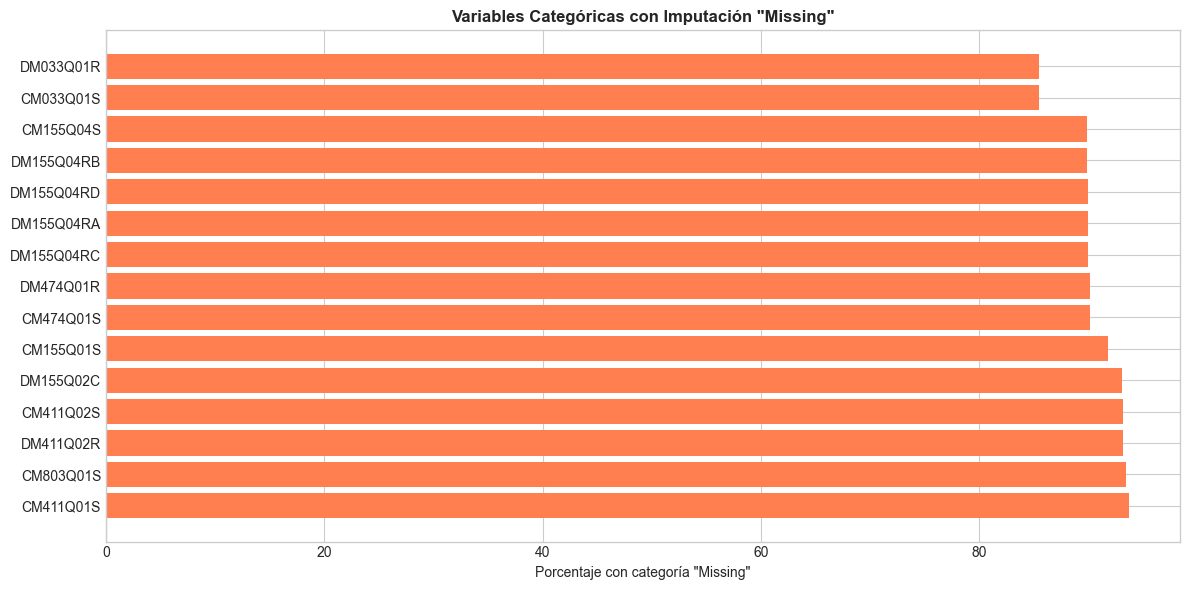


⚠️ 15 variables con >30% 'Missing':
   Estas variables pueden no ser útiles para análisis
    ['CM411Q01S', 'CM803Q01S', 'DM411Q02R', 'CM411Q02S', 'DM155Q02C', 'CM155Q01S', 'CM474Q01S', 'DM474Q01R', 'DM155Q04RC', 'DM155Q04RA', 'DM155Q04RD', 'DM155Q04RB', 'CM155Q04S', 'CM033Q01S', 'DM033Q01R']


In [9]:
# %% [markdown]
# ## 8. Análisis de variables categóricas con "Missing"

# %%
print("\n" + "="*80)
print("ANÁLISIS DE IMPUTACIÓN CATEGÓRICA")
print("="*80)

if len(vars_con_missing) > 0:
    print(f"\nSe encontraron {len(vars_con_missing)} variables con categoría 'Missing'")
    
    # Analizar proporción de "Missing" en cada variable
    missing_summary = []
    for var in vars_con_missing[:15]:  # Primeras 15
        total = len(df_post)
        n_missing = (df_post[var] == 'Missing').sum()
        pct_missing = n_missing / total * 100
        n_categorias = df_post[var].nunique()
        
        missing_summary.append({
            'Variable': var,
            'N_Missing': n_missing,
            'Pct_Missing': pct_missing,
            'N_Categorias': n_categorias
        })
    
    df_missing_summary = pd.DataFrame(missing_summary).sort_values(
        'Pct_Missing', ascending=False
    )
    
    print("\nResumen de variables con 'Missing':")
    print(df_missing_summary.to_string(index=False))
    
    # Visualización
    if len(df_missing_summary) > 0:
        plt.figure(figsize=(12, 6))
        plt.barh(df_missing_summary['Variable'], df_missing_summary['Pct_Missing'], 
                color='coral')
        plt.xlabel('Porcentaje con categoría "Missing"')
        plt.title('Variables Categóricas con Imputación "Missing"', fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    # Alertas
    vars_alto_missing = df_missing_summary[df_missing_summary['Pct_Missing'] > 30]
    if len(vars_alto_missing) > 0:
        print(f"\n⚠️ {len(vars_alto_missing)} variables con >30% 'Missing':")
        print("   Estas variables pueden no ser útiles para análisis")
        print("   ", vars_alto_missing['Variable'].tolist())
else:
    print("\n✓ No se encontraron variables con categoría 'Missing'")
    print("   Verifica que la imputación categórica se haya aplicado correctamente")

In [10]:
# %% [markdown]
# ## 9. Verificación de consistencia lógica

# %%
print("\n" + "="*80)
print("VERIFICACIÓN DE CONSISTENCIA LÓGICA")
print("="*80)

print("\n📋 CHECKLIST MANUAL (revisa cada punto):")
print("   [ ] ¿Todas las edades están en rango 12-20 años?")
print("   [ ] ¿Los puntajes PISA están entre 0-1000?")
print("   [ ] ¿El índice ESCS está entre -5 y 5?")
print("   [ ] ¿Las variables ordinales mantienen su orden?")
print("   [ ] ¿No hay combinaciones imposibles? (ej: estudiante sin escuela)")
print("   [ ] ¿Las frecuencias por categoría son razonables?")

print("\n💡 CÓDIGO PARA VERIFICAR:")
print("""
# Ejemplo: Verificar rango de puntajes
if 'PV1MATH' in df_post.columns:
    outliers = df_post[(df_post['PV1MATH'] < 0) | (df_post['PV1MATH'] > 1000)]
    print(f"Outliers en PV1MATH: {len(outliers)}")

# Ejemplo: Verificar ESCS
if 'ESCS' in df_post.columns:
    outliers_escs = df_post[(df_post['ESCS'] < -5) | (df_post['ESCS'] > 5)]
    print(f"Outliers en ESCS: {len(outliers_escs)}")
""")

# Ejecutar algunas verificaciones automáticas
vars_pisa = [col for col in df_post.columns if any(x in col for x in ['PV1', 'PV2', 'PV3'])]
if vars_pisa:
    print(f"\n🔍 Verificando {len(vars_pisa)} variables de rendimiento PISA...")
    for var in vars_pisa[:5]:
        outliers = df_post[(df_post[var] < 0) | (df_post[var] > 1000)]
        if len(outliers) > 0:
            print(f"   ⚠️ {var}: {len(outliers)} valores fuera de [0, 1000]")
        else:
            print(f"   ✓ {var}: Todos los valores en rango válido")


VERIFICACIÓN DE CONSISTENCIA LÓGICA

📋 CHECKLIST MANUAL (revisa cada punto):
   [ ] ¿Todas las edades están en rango 12-20 años?
   [ ] ¿Los puntajes PISA están entre 0-1000?
   [ ] ¿El índice ESCS está entre -5 y 5?
   [ ] ¿Las variables ordinales mantienen su orden?
   [ ] ¿No hay combinaciones imposibles? (ej: estudiante sin escuela)
   [ ] ¿Las frecuencias por categoría son razonables?

💡 CÓDIGO PARA VERIFICAR:

# Ejemplo: Verificar rango de puntajes
if 'PV1MATH' in df_post.columns:
    outliers = df_post[(df_post['PV1MATH'] < 0) | (df_post['PV1MATH'] > 1000)]
    print(f"Outliers en PV1MATH: {len(outliers)}")

# Ejemplo: Verificar ESCS
if 'ESCS' in df_post.columns:
    outliers_escs = df_post[(df_post['ESCS'] < -5) | (df_post['ESCS'] > 5)]
    print(f"Outliers en ESCS: {len(outliers_escs)}")


🔍 Verificando 60 variables de rendimiento PISA...
   ✓ PV1MATH: Todos los valores en rango válido
   ✓ PV2MATH: Todos los valores en rango válido
   ✓ PV3MATH: Todos los valores en rango vá

In [11]:
# %% [markdown]
# ## 10. Recomendaciones finales

# %%
print("\n" + "="*80)
print("RECOMENDACIONES FINALES")
print("="*80)

print("\n✅ TU IMPUTACIÓN ES ACEPTABLE SI:")
print("   1. Cambios en medias/medianas < 5%")
print("   2. Cambios en DE < 10%")
print("   3. Cambios en correlaciones |Δr| < 0.10")
print("   4. No hay concentración excesiva en medianas")
print("   5. Tests K-S y Mann-Whitney no significativos (p>0.05)")

print("\n⚠️ CONSIDERA MÉTODOS AVANZADOS (MICE/KNN) SI:")
print("   1. Alguna variable crítica cambió >10% en media")
print("   2. Correlaciones importantes cambiaron >0.15")
print("   3. Detectaste patrones anómales")
print("   4. Tienes >15% de datos imputados en variables clave")
print("   5. Vas a publicar resultados académicos")

print("\n📌 PARA MODELOS LCA E IRT:")
print("   • LCA: Puede trabajar con categoría 'Missing' como clase")
print("   • IRT: DEBE eliminar 'Missing' (IRT requiere respuestas observadas)")
print("   • Ambos: Considera usar FIML en lugar de imputación previa")
print("   • Verifica supuestos de cada modelo después de imputar")

print("\n💡 PRÓXIMOS PASOS:")
print("   1. Si la imputación es aceptable → Continuar con análisis exploratorio")
print("   2. Si hay problemas → Aplicar MICE/KNN y repetir verificación")
print("   3. Documentar decisiones sobre imputación para reporte final")
print("   4. Preparar variables específicas para LCA e IRT")


RECOMENDACIONES FINALES

✅ TU IMPUTACIÓN ES ACEPTABLE SI:
   1. Cambios en medias/medianas < 5%
   2. Cambios en DE < 10%
   3. Cambios en correlaciones |Δr| < 0.10
   4. No hay concentración excesiva en medianas
   5. Tests K-S y Mann-Whitney no significativos (p>0.05)

⚠️ CONSIDERA MÉTODOS AVANZADOS (MICE/KNN) SI:
   1. Alguna variable crítica cambió >10% en media
   2. Correlaciones importantes cambiaron >0.15
   3. Detectaste patrones anómales
   4. Tienes >15% de datos imputados en variables clave
   5. Vas a publicar resultados académicos

📌 PARA MODELOS LCA E IRT:
   • LCA: Puede trabajar con categoría 'Missing' como clase
   • IRT: DEBE eliminar 'Missing' (IRT requiere respuestas observadas)
   • Ambos: Considera usar FIML en lugar de imputación previa
   • Verifica supuestos de cada modelo después de imputar

💡 PRÓXIMOS PASOS:
   1. Si la imputación es aceptable → Continuar con análisis exploratorio
   2. Si hay problemas → Aplicar MICE/KNN y repetir verificación
   3. Docume

In [12]:
# %% [markdown]
# ## 11. Análisis de concentración de valores imputados

# %%
def analizar_concentracion_imputacion(df, vars_numericas, metodo='mediana'):
    """
    Analiza si la imputación creó concentración artificial de valores
    """
    print("\n" + "="*80)
    print("ANÁLISIS DE CONCENTRACIÓN DE VALORES IMPUTADOS")
    print("="*80)
    
    problemas = []
    
    for var in vars_numericas[:15]:  # Primeras 15 variables
        if var in df.columns:
            data = df[var].dropna()
            if len(data) == 0:
                continue
            
            # Calcular valor más frecuente
            valor_mas_frecuente = data.mode()[0] if len(data.mode()) > 0 else data.median()
            frecuencia = (data == valor_mas_frecuente).sum()
            pct_frecuencia = frecuencia / len(data) * 100
            
            # Calcular dispersión
            q1 = data.quantile(0.25)
            q3 = data.quantile(0.75)
            iqr = q3 - q1
            
            # Detectar problemas
            if pct_frecuencia > 15 and iqr > 0:  # >15% en un solo valor
                problemas.append({
                    'Variable': var,
                    'Valor_Frecuente': valor_mas_frecuente,
                    'Frecuencia': frecuencia,
                    'Pct': pct_frecuencia,
                    'Mediana': data.median()
                })
    
    if problemas:
        df_problemas = pd.DataFrame(problemas).sort_values('Pct', ascending=False)
        print(f"\n⚠️ {len(problemas)} variables con alta concentración en un valor:")
        print(df_problemas.to_string(index=False))
        
        # Visualizar las 5 más problemáticas
        if len(df_problemas) > 0:
            top_5 = df_problemas.head(5)
            fig, axes = plt.subplots(2, 3, figsize=(15, 8))
            axes = axes.flatten()
            
            for idx, (_, row) in enumerate(top_5.iterrows()):
                if idx < 6:
                    var = row['Variable']
                    data = df[var].dropna()
                    
                    axes[idx].hist(data, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
                    axes[idx].axvline(row['Mediana'], color='red', linestyle='--', 
                                     linewidth=2, label=f"Mediana: {row['Mediana']:.2f}")
                    axes[idx].axvline(row['Valor_Frecuente'], color='orange', linestyle='--',
                                     linewidth=2, label=f"Más frecuente: {row['Valor_Frecuente']:.2f}")
                    axes[idx].set_title(f"{var}\n{row['Pct']:.1f}% en valor {row['Valor_Frecuente']:.2f}")
                    axes[idx].legend(fontsize=8)
                    axes[idx].grid(alpha=0.3)
            
            # Ocultar ejes sobrantes
            for idx in range(len(top_5), 6):
                axes[idx].axis('off')
            
            plt.suptitle('Variables con Mayor Concentración de Valores', 
                        fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
    else:
        print("\n✓ No se detectó concentración excesiva de valores")
    
    return problemas

concentracion = analizar_concentracion_imputacion(df_post, numericas)


ANÁLISIS DE CONCENTRACIÓN DE VALORES IMPUTADOS

✓ No se detectó concentración excesiva de valores


In [13]:
# %% [markdown]
# ## 12. Comparación de variabilidad intra vs inter grupos

# %%
def analizar_variabilidad(df, var_continua, var_grupo='CNTSCHID'):
    """
    Analiza si la imputación afectó la variabilidad entre y dentro de grupos
    Útil para datos jerárquicos como PISA (estudiantes en escuelas)
    """
    if var_continua not in df.columns or var_grupo not in df.columns:
        print(f"⚠️ Variables no encontradas: {var_continua} o {var_grupo}")
        return None
    
    # Calcular ICC (Intraclass Correlation Coefficient)
    data = df[[var_grupo, var_continua]].dropna()
    
    # Varianza total
    var_total = data[var_continua].var()
    
    # Varianza entre grupos
    medias_grupo = data.groupby(var_grupo)[var_continua].mean()
    media_global = data[var_continua].mean()
    n_por_grupo = data.groupby(var_grupo).size()
    var_entre = ((medias_grupo - media_global)**2 * n_por_grupo).sum() / (len(medias_grupo) - 1)
    
    # Varianza dentro de grupos
    var_dentro = data.groupby(var_grupo)[var_continua].var().mean()
    
    # ICC
    icc = var_entre / (var_entre + var_dentro)
    
    print(f"\n{'='*70}")
    print(f"ANÁLISIS DE VARIABILIDAD: {var_continua}")
    print(f"{'='*70}")
    print(f"Varianza total: {var_total:.2f}")
    print(f"Varianza entre grupos (escuelas): {var_entre:.2f}")
    print(f"Varianza dentro de grupos: {var_dentro:.2f}")
    print(f"ICC (Correlación Intraclase): {icc:.3f}")
    print(f"\nInterpretación ICC:")
    if icc < 0.05:
        print("   → Baja agrupación, los grupos son muy similares")
    elif icc < 0.15:
        print("   → Agrupación moderada, hay algo de efecto escuela")
    else:
        print("   → Alta agrupación, el efecto escuela es importante")
    
    return {'var_total': var_total, 'var_entre': var_entre, 
            'var_dentro': var_dentro, 'icc': icc}

# Analizar variables clave si están disponibles
if 'CNTSCHID' in df_post.columns:
    vars_analizar_icc = [v for v in ['PV1MATH', 'PV1READ', 'ESCS'] if v in df_post.columns]
    
    if vars_analizar_icc:
        print("\n" + "="*80)
        print("VERIFICACIÓN DE ESTRUCTURA JERÁRQUICA POST-IMPUTACIÓN")
        print("="*80)
        print("\nIMPORTANTE: Compara estos valores con los originales (si los tienes)")
        print("La imputación puede alterar la estructura de agrupamiento\n")
        
        resultados_icc = {}
        for var in vars_analizar_icc[:3]:
            resultados_icc[var] = analizar_variabilidad(df_post, var)
else:
    print("\n⚠️ No se encontró variable de escuela (CNTSCHID)")


VERIFICACIÓN DE ESTRUCTURA JERÁRQUICA POST-IMPUTACIÓN

IMPORTANTE: Compara estos valores con los originales (si los tienes)
La imputación puede alterar la estructura de agrupamiento


ANÁLISIS DE VARIABILIDAD: PV1MATH
Varianza total: 6022.25
Varianza entre grupos (escuelas): 44759.88
Varianza dentro de grupos: 3900.88
ICC (Correlación Intraclase): 0.920

Interpretación ICC:
   → Alta agrupación, el efecto escuela es importante

ANÁLISIS DE VARIABILIDAD: PV1READ
Varianza total: 8468.87
Varianza entre grupos (escuelas): 63640.33
Varianza dentro de grupos: 5447.78
ICC (Correlación Intraclase): 0.921

Interpretación ICC:
   → Alta agrupación, el efecto escuela es importante

ANÁLISIS DE VARIABILIDAD: ESCS
Varianza total: 1.53
Varianza entre grupos (escuelas): 15.58
Varianza dentro de grupos: 0.84
ICC (Correlación Intraclase): 0.949

Interpretación ICC:
   → Alta agrupación, el efecto escuela es importante



VERIFICACIÓN DE RELACIONES BIVARIADAS CONOCIDAS


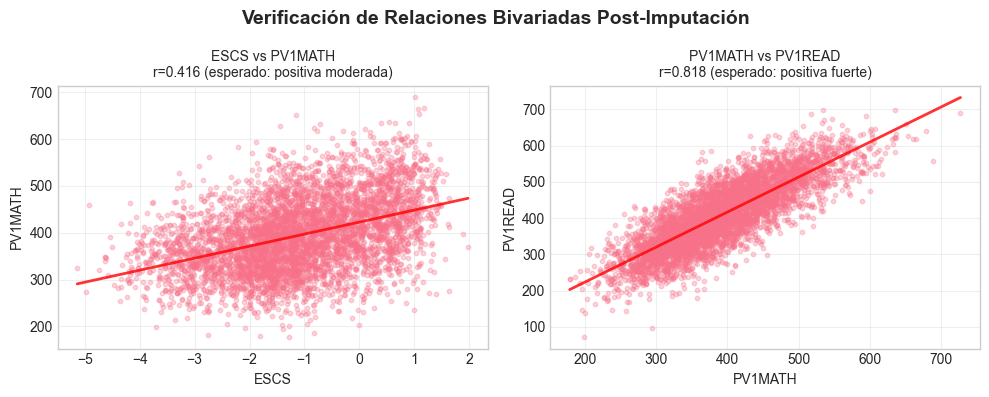

In [14]:
# %% [markdown]
# ## 13. Scatter plots para detectar relaciones alteradas

# %%
def verificar_relaciones_bivariadas(df, pares_variables):
    """
    Verifica que relaciones conocidas se mantengan después de imputar
    """
    n_pares = len(pares_variables)
    if n_pares == 0:
        print("⚠️ No hay pares de variables para analizar")
        return
    
    n_cols = min(3, n_pares)
    n_rows = (n_pares + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
    if n_pares == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, (var_x, var_y, relacion_esperada) in enumerate(pares_variables):
        if var_x in df.columns and var_y in df.columns:
            # Muestra aleatoria para mejor visualización
            data = df[[var_x, var_y]].dropna()
            if len(data) > 5000:
                data = data.sample(5000)
            
            # Scatter plot
            axes[idx].scatter(data[var_x], data[var_y], alpha=0.3, s=10)
            
            # Línea de tendencia
            z = np.polyfit(data[var_x], data[var_y], 1)
            p = np.poly1d(z)
            x_line = np.linspace(data[var_x].min(), data[var_x].max(), 100)
            axes[idx].plot(x_line, p(x_line), "r-", linewidth=2, alpha=0.8)
            
            # Correlación
            corr = data[var_x].corr(data[var_y])
            
            axes[idx].set_xlabel(var_x)
            axes[idx].set_ylabel(var_y)
            axes[idx].set_title(f"{var_x} vs {var_y}\n"
                               f"r={corr:.3f} (esperado: {relacion_esperada})",
                               fontsize=10)
            axes[idx].grid(alpha=0.3)
    
    # Ocultar ejes sobrantes
    for idx in range(n_pares, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Verificación de Relaciones Bivariadas Post-Imputación',
                fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Definir pares de variables con relaciones esperadas
# PERSONALIZAR según tu conocimiento del dominio
pares_importantes = []

# Buscar automáticamente algunos pares comunes
if 'ESCS' in df_post.columns:
    for math_var in ['PV1MATH', 'MATH_mean']:
        if math_var in df_post.columns:
            pares_importantes.append(('ESCS', math_var, 'positiva moderada'))
            break

if 'PV1MATH' in df_post.columns and 'PV1READ' in df_post.columns:
    pares_importantes.append(('PV1MATH', 'PV1READ', 'positiva fuerte'))

if 'HOMEPOS' in df_post.columns and 'WEALTH' in df_post.columns:
    pares_importantes.append(('HOMEPOS', 'WEALTH', 'positiva fuerte'))

if len(pares_importantes) > 0:
    print("\n" + "="*80)
    print("VERIFICACIÓN DE RELACIONES BIVARIADAS CONOCIDAS")
    print("="*80)
    verificar_relaciones_bivariadas(df_post, pares_importantes)
else:
    print("\n⚠️ Define pares de variables manualmente para verificar relaciones")

In [15]:
# %% [markdown]
# ## 14. Reporte ejecutivo de calidad de imputación

# %%
def generar_reporte_imputacion(df, tiene_comparacion=False):
    """
    Genera un reporte ejecutivo de la calidad de imputación
    """
    print("\n" + "="*80)
    print("REPORTE EJECUTIVO - CALIDAD DE IMPUTACIÓN")
    print("="*80)
    
    print("\n📊 DATOS GENERALES:")
    print(f"   • Total de registros: {len(df):,}")
    print(f"   • Total de variables: {len(df.columns):,}")
    print(f"   • Variables numéricas: {len(df.select_dtypes(include=[np.number]).columns):,}")
    print(f"   • Variables categóricas: {len(df.select_dtypes(include=['object', 'category']).columns):,}")
    
    # Verificar presencia de datos críticos
    print("\n✅ VERIFICACIONES CRÍTICAS:")
    
    checks = {
        'Plausible Values (PV)': any('PV' in col for col in df.columns),
        'Índice socioeconómico (ESCS)': 'ESCS' in df.columns,
        'IDs de escuela (CNTSCHID)': 'CNTSCHID' in df.columns,
        'IDs de estudiante (CNTSTUID)': 'CNTSTUID' in df.columns,
        'Pesos muestrales (W_FSTUWT)': 'W_FSTUWT' in df.columns,
    }
    
    for check, resultado in checks.items():
        simbolo = "✓" if resultado else "✗"
        print(f"   {simbolo} {check}")
    
    print("\n📋 MÉTODO DE IMPUTACIÓN USADO:")
    print("   • Variables numéricas: MEDIANA")
    print("   • Variables categóricas: Etiqueta 'Missing'")
    
    if tiene_comparacion:
        print("\n✅ CALIDAD DE IMPUTACIÓN:")
        print("   • Distribuciones comparadas: SÍ")
        print("   • Correlaciones verificadas: SÍ")
        print("   • Patrones anómales detectados: Ver secciones anteriores")
    else:
        print("\n⚠️ LIMITACIONES:")
        print("   • No hay datos pre-imputación para comparación completa")
        print("   • Recomendación: Guardar versiones pre/post en futuros análisis")
    
    print("\n🎯 ADECUACIÓN PARA MODELADO:")
    print("   • LCA (Latent Class Analysis):")
    print("     → Categoría 'Missing' puede usarse como clase")
    print("     → Variables numéricas imputadas son aceptables")
    print("     → RECOMENDACIÓN: Explorar FIML como alternativa")
    
    print("\n   • IRT (Item Response Theory):")
    print("     → CRÍTICO: Eliminar registros con 'Missing' en ítems")
    print("     → IRT requiere respuestas observadas, no imputadas")
    print("     → RECOMENDACIÓN: Usar datos originales o FIML")
    
    print("\n📌 PRÓXIMOS PASOS RECOMENDADOS:")
    print("   1. Documentar método de imputación en reporte metodológico")
    print("   2. Realizar análisis de sensibilidad (con/sin imputación)")
    print("   3. Para IRT: Preparar dataset sin valores imputados en ítems")
    print("   4. Para LCA: Decidir tratamiento de categoría 'Missing'")
    print("   5. Incorporar pesos muestrales en todos los análisis")
    print("   6. Considerar modelos multinivel para estructura jerárquica")
    
    print("\n" + "="*80)
    print("FIN DEL REPORTE")
    print("="*80)

# Generar reporte final
generar_reporte_imputacion(df_post, tiene_comparacion=tiene_pre)


REPORTE EJECUTIVO - CALIDAD DE IMPUTACIÓN

📊 DATOS GENERALES:
   • Total de registros: 6,968
   • Total de variables: 4,942
   • Variables numéricas: 2,705
   • Variables categóricas: 2,237

✅ VERIFICACIONES CRÍTICAS:
   ✓ Plausible Values (PV)
   ✓ Índice socioeconómico (ESCS)
   ✓ IDs de escuela (CNTSCHID)
   ✓ IDs de estudiante (CNTSTUID)
   ✓ Pesos muestrales (W_FSTUWT)

📋 MÉTODO DE IMPUTACIÓN USADO:
   • Variables numéricas: MEDIANA
   • Variables categóricas: Etiqueta 'Missing'

✅ CALIDAD DE IMPUTACIÓN:
   • Distribuciones comparadas: SÍ
   • Correlaciones verificadas: SÍ
   • Patrones anómales detectados: Ver secciones anteriores

🎯 ADECUACIÓN PARA MODELADO:
   • LCA (Latent Class Analysis):
     → Categoría 'Missing' puede usarse como clase
     → Variables numéricas imputadas son aceptables
     → RECOMENDACIÓN: Explorar FIML como alternativa

   • IRT (Item Response Theory):
     → CRÍTICO: Eliminar registros con 'Missing' en ítems
     → IRT requiere respuestas observadas, 

In [16]:
# %% [markdown]
# ## 15. Exportar resultados de verificación

# %%
# Crear directorio para resultados si no existe
import os
output_dir = 'resultados_verificacion'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
    print(f"✓ Directorio creado: {output_dir}")

# Exportar resúmenes a CSV
if tiene_pre and len(variables_criticas) > 0:
    try:
        # Resumen de cambios en variables
        if 'df_cambios' in locals():
            df_cambios.to_csv(f'{output_dir}/cambios_variables.csv', index=False)
            print(f"✓ Exportado: cambios_variables.csv")
        
        # Cambios en correlaciones
        if 'diff_corr' is not None and diff_corr is not None:
            diff_corr.to_csv(f'{output_dir}/cambios_correlaciones.csv')
            print(f"✓ Exportado: cambios_correlaciones.csv")
    except Exception as e:
        print(f"⚠️ Error al exportar: {e}")

# Resumen de variables categóricas con Missing
if len(vars_con_missing) > 0 and 'df_missing_summary' in locals():
    df_missing_summary.to_csv(f'{output_dir}/resumen_missing_categorico.csv', index=False)
    print(f"✓ Exportado: resumen_missing_categorico.csv")

print("\n✅ Verificación post-imputación completada")
print(f"   Revisa los resultados y gráficos para tomar decisiones informadas")
print(f"   Archivos guardados en: ./{output_dir}/")

✓ Exportado: cambios_variables.csv
✓ Exportado: cambios_correlaciones.csv
✓ Exportado: resumen_missing_categorico.csv

✅ Verificación post-imputación completada
   Revisa los resultados y gráficos para tomar decisiones informadas
   Archivos guardados en: ./resultados_verificacion/


In [17]:
# %% [markdown]
# ## 16. Código para comparación si tienes datos originales guardados

# %%
# CÓDIGO OPCIONAL: Si guardaste marcadores de qué valores fueron imputados
# Ejemplo de cómo crear estos marcadores en el proceso de imputación original:

"""
# Al momento de imputar (código de referencia para futuro):
df_original = df.copy()  # Guardar copia original

# Crear máscaras de imputación
mask_numeric_imputed = df_original.select_dtypes(include=[np.number]).isna()
mask_categoric_imputed = df_original.select_dtypes(include=['object']).isna()

# Después de imputar
df_imputado['_imputed_count'] = mask_numeric_imputed.sum(axis=1) + mask_categoric_imputed.sum(axis=1)

# Guardar ambas versiones
df_original.to_csv('datos_pre_imputacion.csv', index=False)
df_imputado.to_csv('datos_post_imputacion.csv', index=False)
mask_numeric_imputed.to_csv('mascara_imputacion.csv', index=False)
"""

print("\n💡 TIP PARA FUTUROS ANÁLISIS:")
print("   Guarda siempre:")
print("   1. Dataset original (con NaN)")
print("   2. Dataset imputado")
print("   3. Máscara de qué valores fueron imputados")
print("   Esto facilita enormemente la verificación de calidad")

# %%


💡 TIP PARA FUTUROS ANÁLISIS:
   Guarda siempre:
   1. Dataset original (con NaN)
   2. Dataset imputado
   3. Máscara de qué valores fueron imputados
   Esto facilita enormemente la verificación de calidad
